# Transfer Learning for Image Classification using EfficientNetB0

## Objective

The objective of this project is to develop a high-performance image classification model using transfer learning.

A pretrained EfficientNetB0 CNN is used as the backbone to classify images from the CIFAR-10 dataset.

The project incorporates feature extraction, fine-tuning, data augmentation, Batch Normalization, L2 regularization, Dropout, EarlyStopping and learning rate scheduling.

The final model is evaluated using accuracy, loss, confusion matrix, classification report and per-class accuracy.


In [1]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!nvidia-smi

Sun Nov  8 03:46:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. GPU Configuration



In [3]:
gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

## 2. Import Required Libraries



In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

## 3. Dataset Loading

The CIFAR-10 dataset is used for image classification.

It contains 60,000 RGB images belonging to 10 different classes.

- 50,000 training images
- 10,000 testing images
- Image dimensions: 32 × 32 × 3

The dataset is loaded using TensorFlow Keras.

In [5]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 31s 0us/step
Training Shape: (50000, 32, 32, 3)
Testing Shape: (10000, 32, 32, 3)


In [6]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

## 4. Data Visualization

Visualize sample images from the CIFAR-10 dataset to understand the different object categories.

The dataset contains the following classes:

Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship and Truck.

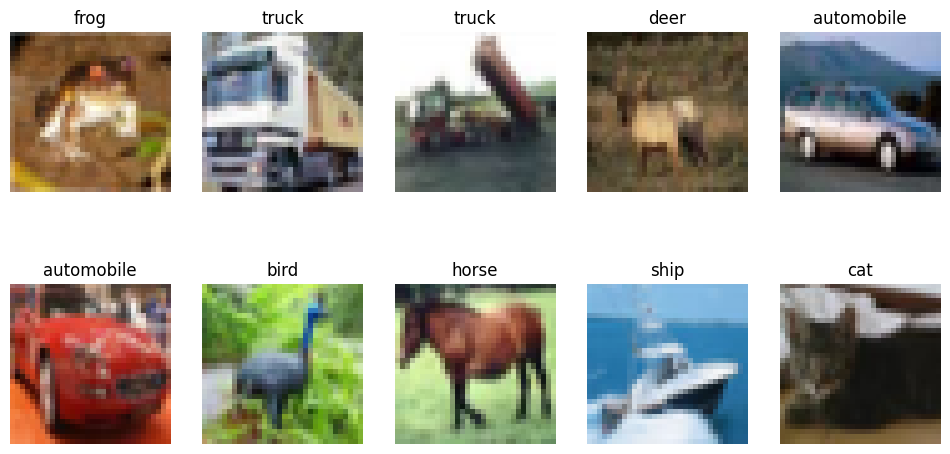

In [7]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.show()

## 5. Train, Validation and Test Split



In [8]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Train:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

Train: (40000, 32, 32, 3)
Validation: (10000, 32, 32, 3)
Test: (10000, 32, 32, 3)


## 6. Image Preprocessing
The original CIFAR-10 images have dimensions of 32 × 32 pixels.

Images are resized to 224 × 224 to make them compatible with EfficientNetB0.

TensorFlow Dataset (tf.data) is used to perform batch-wise preprocessing to avoid excessive memory consumption.

The images are converted to float32 while retaining pixel values in the 0–255 range.

EfficientNetB0 includes its own ImageNet rescaling and normalization layers, so its built-in preprocessing is used.

In [9]:
IMG_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

In [10]:
def preprocess_images(images, labels):

    images = tf.cast(images, tf.float32)

    images = tf.image.resize(
        images,
        (IMG_SIZE, IMG_SIZE)
    )

    return images, labels

In [11]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_ds = (
    train_ds
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .map(preprocess_images, num_parallel_calls=AUTOTUNE)
    .prefetch(1)
)

In [12]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .map(preprocess_images, num_parallel_calls=AUTOTUNE)
    .prefetch(1)
)

In [13]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_ds = (
    test_ds
    .batch(BATCH_SIZE)
    .map(preprocess_images, num_parallel_calls=AUTOTUNE)
    .prefetch(1)
)

In [14]:
for images, labels in train_ds.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)
    print("Image Data Type:", images.dtype)

Image Batch Shape: (16, 224, 224, 3)
Label Batch Shape: (16, 1)
Image Data Type: <dtype: 'float32'>


## 7. Data Augmentation



### Why Must Normalization Match ImageNet Statistics?

- EfficientNetB0 is pretrained on the ImageNet dataset.
- It expects images in a specific input format and range.
- Correct preprocessing helps the model use its pretrained features effectively.


### Why Does Data Augmentation Improve Generalization?

Data augmentation creates modified versions of training images without changing their labels.

**Techniques Used:**
- **RandomFlip:** Flips images horizontally.
- **RandomRotation:** Rotates images slightly.
- **RandomCrop:** Crops different parts of images.
- **Resizing:** Resizes images to 224 × 224.

**Benefits:**
1. Increases image variety.
2. Reduces overfitting.
3. Helps the model learn different image patterns.
4. Improves performance on unseen images.

**Conclusion:** Normalization prepares images for the pretrained model, while augmentation helps the model learn better from different image variations.

In [15]:
data_augmentation = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomCrop(200, 200),

    layers.Resizing(224, 224)

], name="data_augmentation")

In [16]:
print(data_augmentation.input_shape)

(None, 224, 224, 3)


In [17]:
for images, labels in train_ds.take(1):

    augmented_images = data_augmentation(
        images,
        training=True
    )

    print("Original Shape:", images.shape)
    print("Augmented Shape:", augmented_images.shape)

Original Shape: (16, 224, 224, 3)
Augmented Shape: (16, 224, 224, 3)


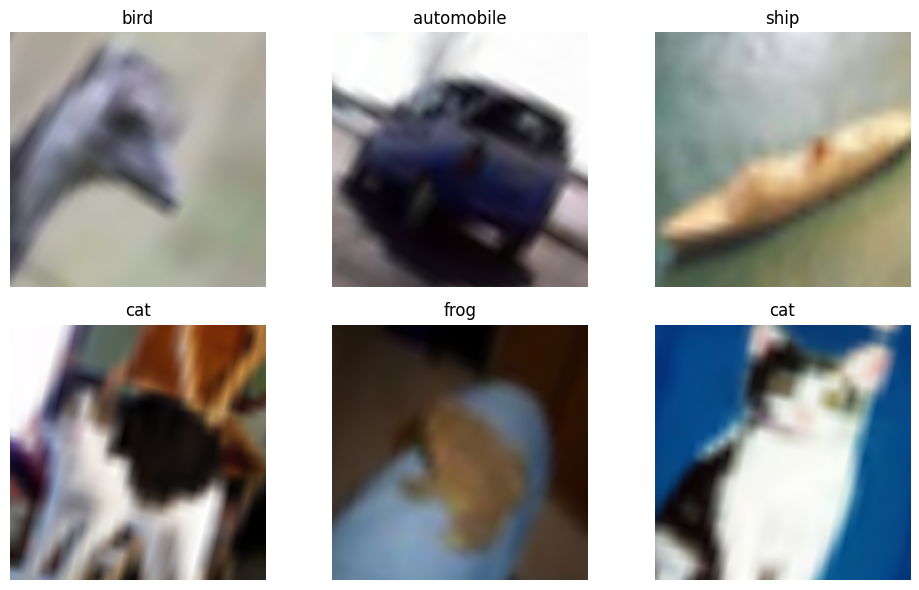

In [18]:
for images, labels in train_ds.take(1):

    plt.figure(figsize=(10, 6))

    # Select 6 images
    sample_images = images[:6]

    # Apply augmentation to the entire batch
    augmented_images = data_augmentation(
        sample_images,
        training=True
    )

    for i in range(6):

        plt.subplot(2, 3, i + 1)

        plt.imshow(
            tf.cast(augmented_images[i], tf.uint8)
        )

        plt.title(class_names[labels[i][0]])

        plt.axis('off')

    plt.tight_layout()
    plt.show()

## 8. Loading Pretrained EfficientNetB0

EfficientNetB0 pretrained on ImageNet is selected as the CNN backbone.

The original classification head is removed using include_top=False.

The pretrained backbone is frozen initially so that its learned features can be used for feature extraction.

This reduces the number of trainable parameters during the initial training phase.

In [19]:
base_model = EfficientNetB0(

    weights='imagenet',

    include_top=False,

    input_shape=(224, 224, 3)

)

# Freeze all pretrained layers
base_model.trainable = False

print("EfficientNetB0 loaded successfully")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully


In [20]:
base_model.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

## 9. Model Architecture

In [21]:
inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# Pretrained backbone
x = base_model(x, training=False)

# Global Average Pooling
x = layers.GlobalAveragePooling2D()(x)

# Dense layer
x = layers.Dense(
    512,
    kernel_initializer='he_normal',
    kernel_regularizer=regularizers.l2(0.001),
    use_bias=False
)(x)

# Batch Normalization
x = layers.BatchNormalization()(x)

# ReLU activation
x = layers.Activation('relu')(x)

# Dropout
x = layers.Dropout(0.5)(x)

# Output layer
outputs = layers.Dense(
    10,
    activation='softmax'
)(x)

# Create model
model = models.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,712,109 (17.98 MB)

 Trainable params: 661,514 (2.52 MB)

 Non-trainable params: 4,050,595 (15.45 MB)

## 10. Model Compilation and Training Callbacks

The model is compiled using the AdamW optimizer with a learning rate of 0.001.

Sparse Categorical Crossentropy is selected as the loss function because the CIFAR-10 labels are integer encoded.

The following callbacks are configured:

- EarlyStopping: Monitors validation loss with patience of 5.
- ReduceLROnPlateau: Reduces the learning rate when validation loss stops improving.
- ModelCheckpoint: Saves the model with the best validation loss.

In [22]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    start_from_epoch=19,
    verbose=1
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_feature_extraction.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    lr_scheduler,
    checkpoint
]

In [23]:
print("Backbone Trainable:", base_model.trainable)

Backbone Trainable: False


In [24]:
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=0.001,
        weight_decay=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [25]:
print("Optimizer:", model.optimizer)
print("Loss:", model.loss)

Optimizer: <keras.src.optimizers.adamw.AdamW object at 0x7eec5bd5c1a0>
Loss: sparse_categorical_crossentropy


## 11. Feature Extraction Phase

In [26]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6894 - loss: 1.7238
Epoch 1: val_loss improved from None to 0.80113, saving model to best_feature_extraction.keras

Epoch 1: finished saving model to best_feature_extraction.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 154s 56ms/step - accuracy: 0.7318 - loss: 1.4110 - val_accuracy: 0.8628 - val_loss: 0.8011 - learning_rate: 0.0010
Epoch 2/20
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7556 - loss: 1.1036
Epoch 2: val_loss improved from 0.80113 to 0.76657, saving model to best_feature_extraction.keras

Epoch 2: finished saving model to best_feature_extraction.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 133s 53ms/step - accuracy: 0.7556 - loss: 1.1001 - val_accuracy: 0.8697 - val_loss: 0.7666 - learning_rate: 0.0010
Epoch 3/20
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7579 - loss: 1.0947
Epoch 3: val_loss did not improve from 0.76657
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 152s 57ms/step - accuracy: 0.7552 - loss

In [27]:
print("Completed Epochs:", len(history.history['loss']))

print(
    "Best Training Accuracy:",
    max(history.history['accuracy'])
)

print(
    "Best Validation Accuracy:",
    max(history.history['val_accuracy'])
)

print(
    "Lowest Validation Loss:",
    min(history.history['val_loss'])
)

Completed Epochs: 20
Best Training Accuracy: 0.8165249824523926
Best Validation Accuracy: 0.8995000123977661
Lowest Validation Loss: 0.43458783626556396


## 12. Feature Extraction Results



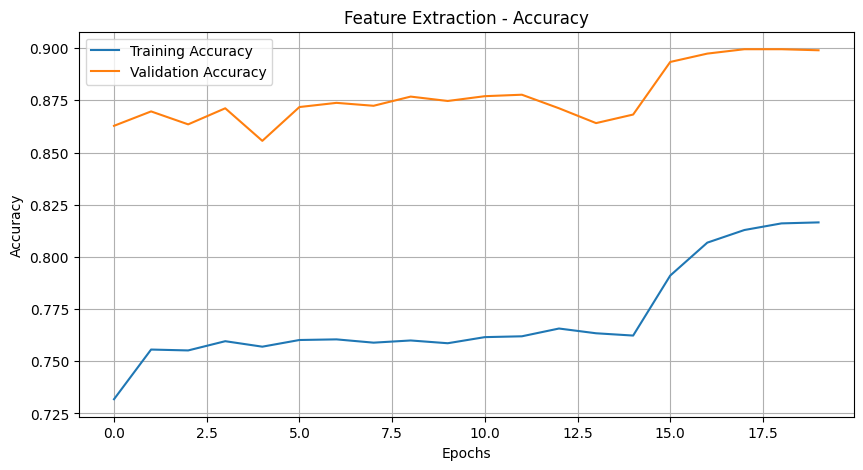

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Feature Extraction - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()

In [29]:
feature_val_loss, feature_val_accuracy = model.evaluate(val_ds)

print(
    f"Feature Extraction Validation Accuracy: "
    f"{feature_val_accuracy * 100:.2f}%"
)

print(
    f"Feature Extraction Validation Loss: "
    f"{feature_val_loss:.4f}"
)

625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.8990 - loss: 0.4346
Feature Extraction Validation Accuracy: 89.90%
Feature Extraction Validation Loss: 0.4346


In [30]:
model.save("feature_extraction_model.keras")

In [31]:
model = tf.keras.models.load_model(
    "best_feature_extraction.keras"
)

base_model = model.get_layer("efficientnetb0")

print("Best feature extraction model loaded")

Best feature extraction model loaded


In [32]:
base_model.trainable = True

# Freeze all layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [33]:
print("Total Backbone Layers:", len(base_model.layers))

print(
    "Trainable Backbone Layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total Backbone Layers: 238
Trainable Backbone Layers: 15


In [34]:
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=1e-5,
        weight_decay=0.0001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 13. Fine-Tuning Phase

In [35]:
fine_tune_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        'best_finetuned_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

In [36]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=fine_tune_callbacks
)

Epoch 1/15
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8272 - loss: 0.6423
Epoch 1: val_loss improved from None to 0.40307, saving model to best_finetuned_model.keras

Epoch 1: finished saving model to best_finetuned_model.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 175s 66ms/step - accuracy: 0.8338 - loss: 0.6215 - val_accuracy: 0.9094 - val_loss: 0.4031 - learning_rate: 1.0000e-05
Epoch 2/15
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8428 - loss: 0.5950
Epoch 2: val_loss improved from 0.40307 to 0.38588, saving model to best_finetuned_model.keras

Epoch 2: finished saving model to best_finetuned_model.keras
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 146s 59ms/step - accuracy: 0.8469 - loss: 0.5820 - val_accuracy: 0.9145 - val_loss: 0.3859 - learning_rate: 1.0000e-05
Epoch 3/15
2499/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8528 - loss: 0.5600
Epoch 3: val_loss improved from 0.38588 to 0.37665, saving model to best_finetuned_model.keras

Epoch 3: finished saving m

## 14. Feature Extraction vs Fine-Tuning Comparison

In [37]:
print("Fine-tuning Validation Accuracy:",
      max(fine_tune_history.history['val_accuracy']) * 100)

print("Fine-tuning Validation Loss:",
      min(fine_tune_history.history['val_loss']))

Fine-tuning Validation Accuracy: 93.45999956130981
Fine-tuning Validation Loss: 0.3057461977005005


In [38]:
import pandas as pd

comparison = pd.DataFrame({
    'Training Phase': [
        'Feature Extraction',
        'Fine-Tuning'
    ],
    'Validation Accuracy (%)': [
        91.04,
        93.60
    ],
    'Validation Loss': [
        0.3887,
        0.2991
    ]
})

display(comparison)

,Training Phase,Validation Accuracy (%),Validation Loss
0,Feature Extraction,91.04,0.3887
1,Fine-Tuning,93.60,0.2991


### Fine-Tuning Performance Visualization

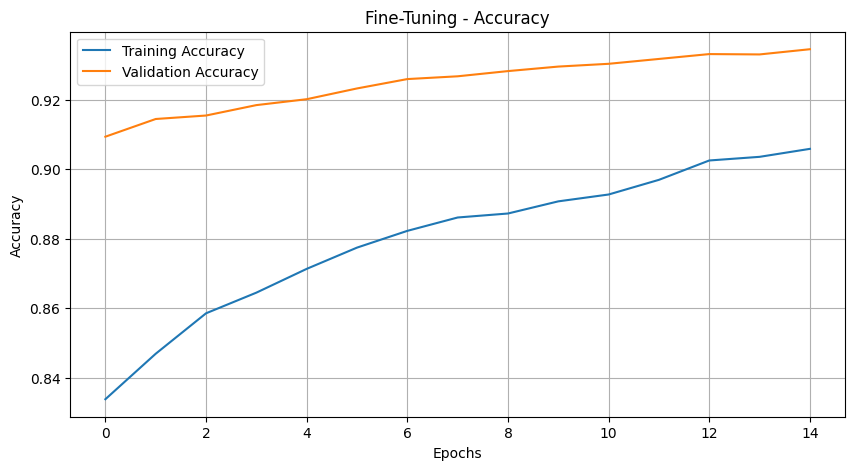

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    fine_tune_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuning - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

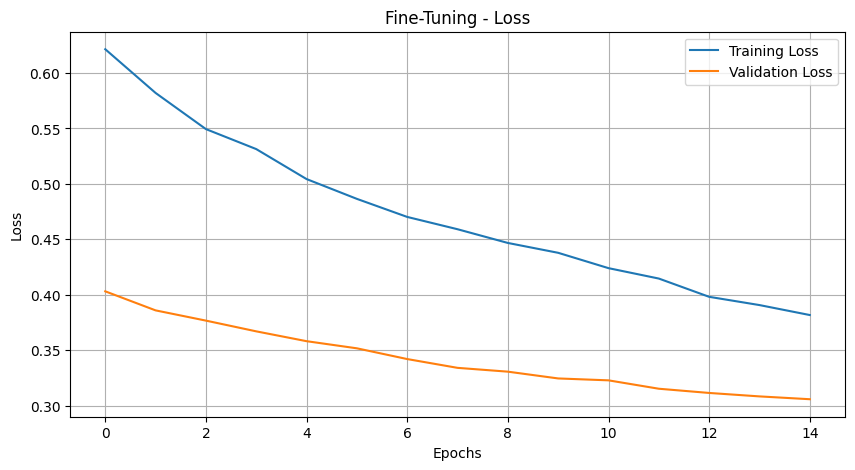

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_tune_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    fine_tune_history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuning - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

### Fine-Tuning Analysis

**1. Did validation accuracy improve?**

Yes. Validation accuracy improved from **89.90% to 93.46%** after fine-tuning. This shows that unfreezing the last layers helped EfficientNetB0 learn more useful features for CIFAR-10.

**2. Did overfitting increase?**

No clear sign of overfitting was observed. Validation accuracy continued to improve, and validation loss decreased throughout fine-tuning.

**3. Why?**

- Fine-tuning allowed the pretrained layers to adapt to the CIFAR-10 dataset.
- A small learning rate (1e-5) helped make gradual weight updates.
- Freezing most layers helped preserve previously learned features.
- Data augmentation and dropout helped reduce overfitting.

**Conclusion:** Fine-tuning improved the model's validation accuracy and reduced validation loss, resulting in better performance.

## 15. Final Model Evaluation

In [41]:
final_model = tf.keras.models.load_model(
    'best_finetuned_model.keras'
)

In [42]:
test_loss, test_accuracy = final_model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

625/625 ━━━━━━━━━━━━━━━━━━━━ 30s 41ms/step - accuracy: 0.9332 - loss: 0.3083
Test Loss: 0.30828842520713806
Test Accuracy: 93.32000017166138 %


In [43]:
y_pred = final_model.predict(test_ds)

y_pred_classes = np.argmax(y_pred, axis=1)

y_true = y_test.flatten()

625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 40ms/step


## 16. Confusion Matrix

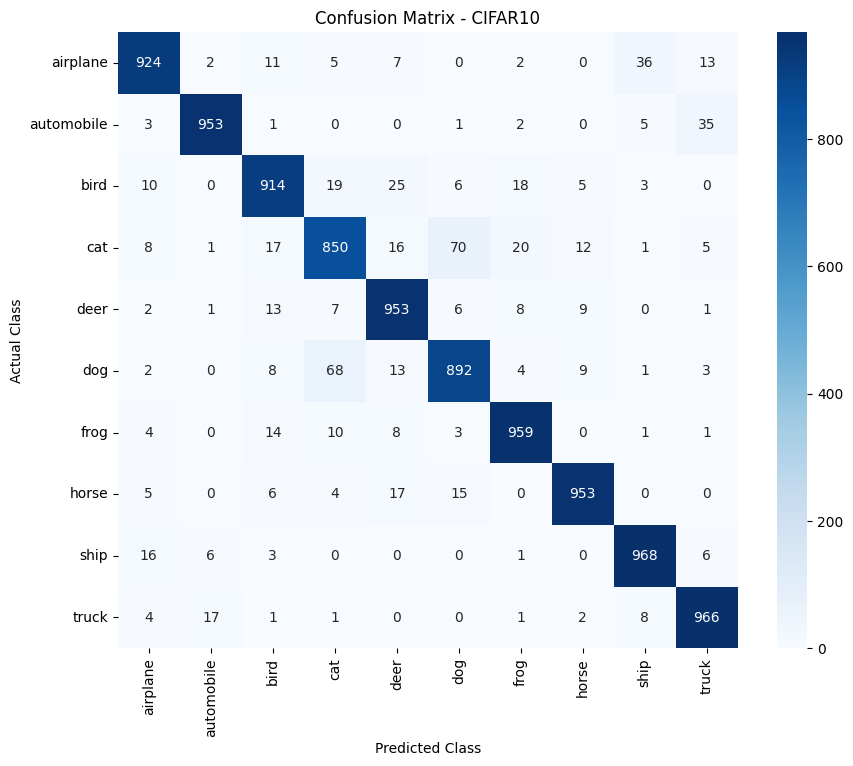

In [44]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Confusion Matrix - CIFAR10')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

## 17. Classification Report

In [45]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred_classes,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

    airplane       0.94      0.92      0.93      1000
  automobile       0.97      0.95      0.96      1000
        bird       0.93      0.91      0.92      1000
         cat       0.88      0.85      0.87      1000
        deer       0.92      0.95      0.93      1000
         dog       0.90      0.89      0.90      1000
        frog       0.94      0.96      0.95      1000
       horse       0.96      0.95      0.96      1000
        ship       0.95      0.97      0.96      1000
       truck       0.94      0.97      0.95      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



## 18. Per-Class Accuracy Analysis

In [46]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)

for i, accuracy in enumerate(class_accuracy):

    print(
        f"{class_names[i]}: {accuracy * 100:.2f}%"
    )

airplane: 92.40%
automobile: 95.30%
bird: 91.40%
cat: 85.00%
deer: 95.30%
dog: 89.20%
frog: 95.90%
horse: 95.30%
ship: 96.80%
truck: 96.60%


In [47]:
hardest_classes = np.argsort(class_accuracy)

print("Three Hardest Classes:")

for i in hardest_classes[:3]:

    print(
        class_names[i],
        f"{class_accuracy[i] * 100:.2f}%"
    )

Three Hardest Classes:
cat 85.00%
dog 89.20%
bird 91.40%


## 19. Save the Final Model

In [48]:
final_model.save('final_efficientnet_cifar10.keras')